# 03 · Arbres d'Auvergne-Rhône-Alpes

**Objectif** : localiser les arbres de la région. Pour une station Citiz, un arbre est à la fois une **contrainte** (un emplacement planté n'est pas une place de stationnement) et un **indicateur d'environnement** (ombre, îlot de fraîcheur, rue apaisée).

Il n'existe **pas d'inventaire national** des arbres urbains. On combine donc :

- **OpenStreetMap** (`natural=tree`), toute la région, licence ODbL. Couverture très inégale : elle dépend du travail des contributeurs locaux, et certaines communes n'ont aucun arbre cartographié ;
- l'**inventaire des arbres d'alignement de la Métropole de Lyon** (data.grandlyon.com), relevé par la collectivité, avec essence, hauteur, circonférence et année de plantation. Il ne couvre que les arbres de voirie, pas ceux des parcs.

D'autres métropoles publient leur inventaire (Grenoble, Saint-Étienne…) ; elles ne sont pas encore intégrées.

In [1]:
import json
import re
import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(d for d in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (d / "siting-data" / "siting_sources.py").is_file())
sys.path.insert(0, str(ROOT / "siting-data"))
from siting_sources import assign_department, download, fetch_overpass, load_departments, load_region, module_paths

ROOT, RAW, CLEAN = module_paths()
region = load_region()
departments = load_departments()

## 1. Télécharger les arbres OSM

Un arbre isolé est un **point** (`node`) OSM. Les alignements (`natural=tree_row`) et les bois (`natural=wood`, `landuse=forest`) sont des lignes et des surfaces, hors du périmètre de ce notebook.

La requête Overpass couvre la zone `FR-ARA`. La réponse (plusieurs dizaines de Mo) est conservée dans `data/raw/`.

In [2]:
OVERPASS_QUERY = '''
[out:json][timeout:900];
area["ISO3166-2"="FR-ARA"]->.region;
node["natural"="tree"](area.region);
out;
'''
payload = fetch_overpass(OVERPASS_QUERY, RAW / "osm_trees_aura.json", description="OSM natural=tree nodes AURA")
OSM_SNAPSHOT = payload["osm3s"]["timestamp_osm_base"]
print(f"OSM snapshot: {OSM_SNAPSHOT}; {len(payload['elements'])} tree nodes")

OSM snapshot: 2026-10-20T13:08:19Z; 382078 tree nodes


## 2. Mettre à plat et nettoyer les attributs OSM

Attributs utiles, tous facultatifs dans OSM :

| Tag OSM | Sens | Nettoyage |
|---|---|---|
| `genus`, `species`, `species:fr` | genre, espèce (latin), nom français | texte conservé tel quel |
| `height` | hauteur | nombre de mètres extrait (`12`, `12 m`, `12.5`) ; sinon inconnu |
| `circumference` | circonférence du tronc | en mètres dans OSM, convertie en cm |
| `leaf_type`, `leaf_cycle` | feuillu / conifère, caduc / persistant | texte |
| `start_date` | date de plantation | année sur 4 chiffres si présente |
| `denotation` | rôle de l'arbre (`avenue`, `urban`, `landmark`…) | texte |

Une valeur non interprétable devient **inconnue**, jamais zéro. Les hauteurs supérieures à 60 m sont traitées comme des erreurs de saisie (l'arbre le plus haut de France mesure environ 60 m).

In [3]:
def parse_metres(value, max_value):
    """Return a positive number of metres written as '12', '12 m' or '12,5', otherwise missing."""
    if value is None or pd.isna(value):
        return pd.NA
    match = re.fullmatch(r"\s*(\d+(?:[.,]\d+)?)\s*(m)?\s*", str(value))
    if not match:
        return pd.NA
    number = float(match.group(1).replace(",", "."))
    return number if 0 < number <= max_value else pd.NA

def parse_year(value):
    match = re.search(r"\b(1[5-9]\d\d|20[0-2]\d)\b", str(value)) if value is not None and pd.notna(value) else None
    return int(match.group(1)) if match else pd.NA

rows = []
for element in payload["elements"]:
    tags = element.get("tags", {})
    rows.append({
        "tree_uid": f"osm:node/{element['id']}", "source": "osm", "source_id": str(element["id"]),
        "lon": element["lon"], "lat": element["lat"],
        "genus": tags.get("genus"), "species": tags.get("species"), "name_fr": tags.get("species:fr"),
        "leaf_type": tags.get("leaf_type"), "leaf_cycle": tags.get("leaf_cycle"), "denotation": tags.get("denotation"),
        "height_raw": tags.get("height"), "circumference_raw": tags.get("circumference"), "start_date": tags.get("start_date"),
    })
osm = pd.DataFrame(rows)
osm["height_m"] = osm["height_raw"].map(lambda v: parse_metres(v, 60)).astype("Float64")
osm["circumference_cm"] = (osm["circumference_raw"].map(lambda v: parse_metres(v, 20)).astype("Float64") * 100).round()
osm["planting_year"] = osm["start_date"].map(parse_year).astype("Int64")
assert osm["tree_uid"].is_unique
filled = osm[["genus", "species", "name_fr", "leaf_type", "height_raw", "height_m", "circumference_cm", "planting_year"]].notna().mean()
display((100 * filled).round(1).rename("% filled").to_frame())
print("Height values rejected:", int(osm["height_raw"].notna().sum() - osm["height_m"].notna().sum()))

,% filled
genus,16.5
species,16.0
name_fr,4.7
leaf_type,30.4
height_raw,5.6
height_m,5.6
circumference_cm,4.5
planting_year,9.3


Height values rejected: 4


## 3. Télécharger l'inventaire de la Métropole de Lyon

Le portail data.grandlyon.com publie la couche en **WFS** (*Web Feature Service*), un standard d'API géographique. Le serveur limite le nombre d'objets par requête : on lit la couche par pages de 50 000, triées par identifiant (`gid`) pour qu'aucune page ne se recoupe.

Le champ `codegenre` distingue : `2` arbre, `1` souche, `0` emplacement libre (fosse sans arbre). Seuls les **arbres** sont gardés ; les autres lignes sont comptées.

In [4]:
LYON_WFS = "https://data.grandlyon.com/geoserver/metropole-de-lyon/ows"
LYON_LAYER = "metropole-de-lyon:abr_arbres_alignement.abrarbre"
PAGE_SIZE = 50000

features, start = [], 0
while True:
    page_path = download(LYON_WFS, RAW / f"lyon_trees_{start:06d}.json", description="Métropole de Lyon arbres d'alignement (WFS page)",
                         params={"SERVICE": "WFS", "VERSION": "2.0.0", "REQUEST": "GetFeature", "TYPENAMES": LYON_LAYER,
                                 "OUTPUTFORMAT": "application/json", "SRSNAME": "EPSG:4326", "COUNT": PAGE_SIZE,
                                 "STARTINDEX": start, "SORTBY": "gid"})
    page = json.loads(page_path.read_text())
    features.extend(page["features"])
    if len(page["features"]) < PAGE_SIZE:
        break
    start += PAGE_SIZE

lyon_raw = pd.DataFrame([{**f["properties"], "lon": f["geometry"]["coordinates"][0], "lat": f["geometry"]["coordinates"][1]}
                         for f in features if f.get("geometry")])
print(f"Lyon features: {len(features)} (server total {page['totalFeatures']}); with geometry: {len(lyon_raw)}")
assert len(features) == page["totalFeatures"] and lyon_raw["gid"].is_unique
lyon_raw["codegenre"].map({2: "tree", 1: "stump", 0: "empty pit"}).value_counts(dropna=False)

Lyon features: 112344 (server total 112344); with geometry: 112344


codegenre
tree         106476
empty pit      3384
stump          2484
Name: count, dtype: int64

## 4. Nettoyer l'inventaire lyonnais

- Les mesures à **0** (hauteur, circonférence) signifient « non mesuré » : elles deviennent inconnues.
- Les mêmes plafonds qu'OSM s'appliquent (60 m de hauteur, 2 000 cm de circonférence).
- `identifiant` est l'identifiant métier de l'arbre ; on vérifie son unicité avant de l'utiliser comme clé.

In [5]:
lyon = lyon_raw.loc[lyon_raw["codegenre"] == 2].copy()
print("duplicated identifiant:", lyon["identifiant"].duplicated().sum())
lyon_trees = pd.DataFrame({
    "tree_uid": "grandlyon:" + lyon["identifiant"].astype(str), "source": "grandlyon",
    "source_id": lyon["identifiant"].astype(str), "lon": lyon["lon"], "lat": lyon["lat"],
    "genus": lyon["genre"], "species": lyon["essence"], "name_fr": lyon["essencefrancais"],
    "height_m": lyon["hauteurtotale_m"].where(lyon["hauteurtotale_m"].between(0, 60, inclusive="right")).astype("Float64"),
    "circumference_cm": lyon["circonference_cm"].where(lyon["circonference_cm"].between(0, 2000, inclusive="right")).astype("Float64"),
    "planting_year": lyon["anneeplantation"].astype("Int64"), "insee_code": lyon["codeinsee"].astype("Int64").astype(str),
    "street": lyon["nomvoie"], "location_type": lyon["localisation"],
})
lyon_trees = lyon_trees.drop_duplicates("tree_uid")
display(lyon_trees[["height_m", "circumference_cm", "planting_year"]].describe().round(1))
lyon_trees["genus"].value_counts().head(10).rename("trees").to_frame()

duplicated identifiant: 0


,height_m,circumference_cm,planting_year
count,106474.0,104086.0,95981.0
mean,9.0,69.5,2002.1
std,5.4,58.2,29.7
min,1.0,1.0,1740.0
25%,6.0,25.0,1999.0
50%,7.0,51.0,2010.0
75%,11.0,94.0,2019.0
max,55.0,606.0,2026.0


,trees
genus,
Platanus,17902
Acer,14499
Quercus,7731
Fraxinus,7610
Celtis,7348
Tilia,6345
Prunus,5399
Pirus,4287
Sophora,4149


## 5. Repérer les arbres présents dans les deux sources

Une partie des arbres de Lyon est aussi cartographiée dans OSM, parfois importée depuis cet inventaire. Un arbre OSM situé **à moins de 3 m** d'un arbre de l'inventaire est considéré comme le même arbre : il est marqué `countable = False` et `duplicate_of` pointe vers l'arbre de l'inventaire, plus riche en attributs.

Le seuil de 3 m correspond à l'écart de positionnement courant entre deux relevés ; deux arbres d'alignement sont en général espacés de 5 à 10 m.

In [6]:
DUPLICATE_DISTANCE_M = 3
osm_metric = gpd.GeoDataFrame(osm[["tree_uid"]], geometry=gpd.points_from_xy(osm["lon"], osm["lat"]), crs=4326).to_crs(2154)
lyon_metric = gpd.GeoDataFrame(lyon_trees[["tree_uid"]], geometry=gpd.points_from_xy(lyon_trees["lon"], lyon_trees["lat"]), crs=4326).to_crs(2154)
near = gpd.sjoin_nearest(osm_metric, lyon_metric, how="inner", max_distance=DUPLICATE_DISTANCE_M,
                         distance_col="distance_m", lsuffix="osm", rsuffix="lyon")
near = near.sort_values("distance_m").drop_duplicates("tree_uid_osm").drop_duplicates("tree_uid_lyon")
duplicate_of = near.set_index("tree_uid_osm")["tree_uid_lyon"]
osm["duplicate_of"] = osm["tree_uid"].map(duplicate_of)
osm["countable"] = osm["duplicate_of"].isna()
print(f"OSM trees matched to the Lyon inventory within {DUPLICATE_DISTANCE_M} m: {len(duplicate_of)}")

OSM trees matched to the Lyon inventory within 3 m: 34624


## 6. Assembler, filtrer la région, rattacher le département

Le département est trouvé par jointure spatiale avec les contours simplifiés ; à défaut, le département le plus proche à 2 km au plus. Pour l'inventaire lyonnais, le code INSEE de la commune, plus fiable, donne directement le département.

In [7]:
lyon_trees["countable"], lyon_trees["duplicate_of"] = True, pd.NA
COLUMNS = ["tree_uid", "source", "source_id", "genus", "species", "name_fr", "leaf_type", "leaf_cycle", "denotation",
           "height_m", "circumference_cm", "planting_year", "street", "location_type", "insee_code",
           "department_code", "department_name", "department_method", "lon", "lat", "countable", "duplicate_of"]
trees = pd.concat([osm, lyon_trees], ignore_index=True)
trees = gpd.GeoDataFrame(trees, geometry=gpd.points_from_xy(trees["lon"], trees["lat"]), crs=4326)
inside = trees.within(region)
print("Outside the IGN outline:", trees.loc[~inside, "source"].value_counts().to_dict())
trees = assign_department(trees.loc[inside], departments)
# Lyon inventory rows carry their INSEE code: it is more reliable than simplified contours near the edges.
from_inventory = trees["source"] == "grandlyon"
trees.loc[from_inventory, ["department_code", "department_name", "department_method"]] = ["69", "Rhône", "insee_code"]
trees = pd.DataFrame(trees.drop(columns="geometry")).reindex(columns=COLUMNS)
trees["osm_snapshot_utc"] = OSM_SNAPSHOT
assert trees["tree_uid"].is_unique
print(trees["source"].value_counts().to_dict(), "| countable:", int(trees["countable"].sum()))
trees["department_method"].value_counts(dropna=False)

Outside the IGN outline: {'osm': 20}


{'osm': 382058, 'grandlyon': 106476} | countable: 453910


department_method
within        380909
insee_code    106476
nearest         1149
Name: count, dtype: int64

## 7. Couverture par département

Le nombre d'arbres recensés **par km²** montre surtout **où les arbres sont cartographiés**, pas où ils poussent. À utiliser comme indicateur relatif à l'intérieur d'une zone bien couverte (Lyon, Grenoble…), pas pour comparer des départements entre eux.

In [8]:
areas_km2 = departments.set_index("department_code").to_crs(2154).area / 1e6
coverage = trees.loc[trees["countable"]].groupby(["department_code", "department_name"]).agg(
    trees=("tree_uid", "size"),
    osm=("source", lambda s: (s == "osm").sum()),
    grandlyon=("source", lambda s: (s == "grandlyon").sum()),
    with_genus=("genus", "count"),
).reset_index()
coverage["trees_per_km2"] = (coverage["trees"] / coverage["department_code"].map(areas_km2)).round(1)
coverage

,department_code,department_name,trees,osm,grandlyon,with_genus,trees_per_km2
0,01,Ain,28764,28764,0,92,5.0
1,03,Allier,14798,14798,0,130,2.0
2,07,Ardèche,5299,5299,0,343,1.0
3,15,Cantal,2994,2994,0,3,0.5
4,26,Drôme,30052,30052,0,378,4.6
5,38,Isère,96142,96142,0,38825,12.2
6,42,Loire,16439,16439,0,679,3.4
7,43,Haute-Loire,6418,6418,0,13,1.3
8,63,Puy-de-Dôme,21498,21498,0,182,2.7
9,69,Rhône,158146,51670,106476,110810,48.6


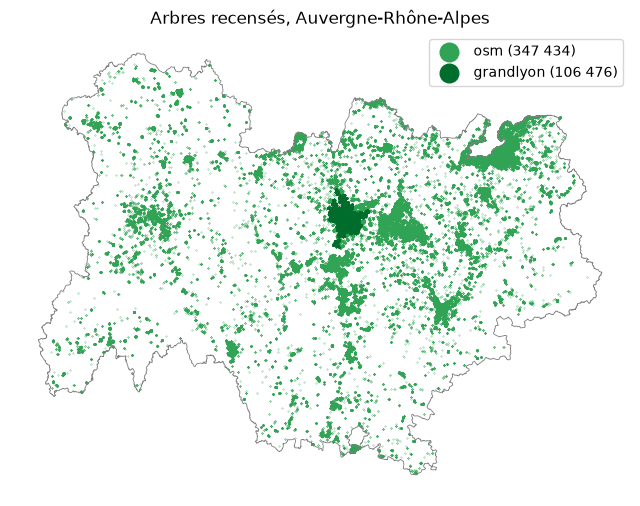

In [9]:
fig, ax = plt.subplots(figsize=(8, 8))
gpd.GeoSeries([region], crs=4326).boundary.plot(ax=ax, color="grey", linewidth=0.6)
for source, color in [("osm", "#31a354"), ("grandlyon", "#006d2c")]:
    subset = trees.loc[trees["countable"] & (trees["source"] == source)]
    ax.scatter(subset["lon"], subset["lat"], s=0.05, color=color, label=f"{source} ({len(subset):,})".replace(",", " "))
ax.set_title("Arbres recensés, Auvergne-Rhône-Alpes")
ax.legend(markerscale=60)
ax.set_axis_off()
plt.show()

## 8. Export et relecture

In [10]:
output_path = CLEAN / "trees_aura.csv"
trees.to_csv(output_path, index=False)
reread = pd.read_csv(output_path, dtype={"insee_code": str, "department_code": str, "source_id": str}, low_memory=False)
assert len(reread) == len(trees) and reread["tree_uid"].is_unique
assert reread["height_m"].dropna().between(0, 60, inclusive="right").all()
assert reread.loc[~reread["countable"], "duplicate_of"].notna().all()
print(f"Wrote {output_path.relative_to(ROOT)}: {len(reread)} rows, {reread.shape[1]} columns, "
      f"{output_path.stat().st_size / 1e6:.0f} MB")

Wrote siting-data/data/clean/trees_aura.csv: 488534 rows, 23 columns, 72 MB
